# ⚽🔬 Controlled Possession vs. Deflections & Sensor Dropout
## Exploratory Data Analysis & Boundary Diagnostics (BAR-ATH)

In **More than a Hack 2027 — Phase 1**, the ranking metric is **`spellF1`** (temporal IoU matching of maximal contiguous possession intervals), NOT frame accuracy.

### Why this notebook exists
As proven by `baseline_raw` (`spellF1 = 0.0378`, 131 possessions vs. true 17):
- Giving the ball to whoever is closest to it creates **flickering** during tackles, rebounds, and deflections.
- Under official football rules ([CHALLENGE.md](../CHALLENGE.md)), **a simple touch, deflection, or aerial duel without subsequent control does NOT change possession**.
- Furthermore, the ball is missing on **41% of graded frames**.

In this notebook, we:
1. **Load and dissect the 17 public Ground Truth possessions** in the 5-minute slice (frames 11,185 to 18,684).
2. **Extract frame-by-frame player-ball proximities and kinematics** ($d_H$, $d_A$, $v_{\text{ball}}$).
3. **Visualize boundary time-series profiles** (distance curves & ball velocity) at turnovers vs. deflections.
4. **Implement the Kinematic Dwell Horizon filter** and sweep dwell thresholds ($5\text{f}$ to $30\text{f}$).
5. **Benchmark the results against `baseline_smooth50`** using official `possession_metrics`.

--- 
## 1. Environment & Module Imports

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

import games
import evaluation.possession_metrics as pm
from starter.baseline import team_of_each_track, FIELD_SEP, GROUP_SEP, MISSING, HOME, AWAY, NOBODY

print("Environment initialized successfully!")

Environment initialized successfully!


--- 
## 2. Load the Public 5-Minute Ground Truth (17 Possessions)

In [2]:
START_FRAME = 11185
END_FRAME = 18684
N_FRAMES = END_FRAME - START_FRAME + 1
FPS = 25

gt_path = os.path.join('..', 'evaluation', 'gt', 'BAR-ATH_possession_gt_public.csv')
gt_table = pm.read_label_csv(gt_path)
gt_codes_full = pm.label_codes(gt_table)
gt_codes_slice = gt_codes_full[START_FRAME:END_FRAME + 1]

# Extract GT segments
gt_runs = pm.valid_runs(gt_codes_slice)
gt_spells = pm.possession_spells(gt_codes_slice, gt_runs)

print(f"Public Ground Truth: {N_FRAMES} frames ({N_FRAMES/FPS:.1f}s = {N_FRAMES/(FPS*60):.1f} min)")
print(f"Possessions in GT: {len(gt_spells)} (Official benchmark = 17 possessions)")

spells_summary = []
for idx, (start, stop, code) in enumerate(gt_spells):
    dur_s = (stop - start) / FPS
    team = 'Barcelona (H)' if code == pm.H else 'Athletic Club (A)'
    spells_summary.append({
        'Spell #': idx + 1,
        'Team': team,
        'Start Frame': START_FRAME + start,
        'End Frame': START_FRAME + stop - 1,
        'Frames': stop - start,
        'Duration (s)': f"{dur_s:.1f}s"
    })

pd.DataFrame(spells_summary).head(10)

Public Ground Truth: 7500 frames (300.0s = 5.0 min)
Possessions in GT: 17 (Official benchmark = 17 possessions)


,Spell #,Team,Start Frame,End Frame,Frames,Duration (s)
0,1,Athletic Club (A),11185,11350,166,6.6s
1,2,Barcelona (H),11351,11552,202,8.1s
2,3,Athletic Club (A),11553,11623,71,2.8s
3,4,Barcelona (H),11624,12664,1041,41.6s
4,5,Athletic Club (A),12665,12850,186,7.4s
5,6,Barcelona (H),12989,13703,715,28.6s
6,7,Athletic Club (A),13704,13784,81,3.2s
7,8,Barcelona (H),13785,14845,1061,42.4s
8,9,Athletic Club (A),14846,15345,500,20.0s
9,10,Barcelona (H),15346,15364,19,0.8s


--- 
## 3. Extract Tracking & Compute Spatial-Kinematic Features

For each frame, we compute:
- Ball pitch coordinates $(x_{\text{ball}}, y_{\text{ball}})$ and instantaneous ball speed $v_{\text{ball}}$.
- Distance from ball to closest Home player: $d(H_1, b)$.
- Distance from ball to closest Away player: $d(A_1, b)$.
- Proximity differential $\Delta d = d(A_1, b) - d(H_1, b)$ (positive indicates Barcelona $H$ is closer).

In [3]:
paths = games.asset_paths(source='tactical')
team_of_track = team_of_each_track(paths['atd_meta'])
pitch_len, pitch_wid = games.GAMES['BAR-ATH']['pitch']  # 105.3m x 68.0m

ball_xy = np.full((N_FRAMES, 2), np.nan)
min_dist_H = np.full(N_FRAMES, np.nan)
min_dist_A = np.full(N_FRAMES, np.nan)
nearest_team = np.full(N_FRAMES, NOBODY, dtype=np.int8)

print("Streaming tracking slice from ATD...")
with open(paths['atd_raw']) as handle:
    for line_idx, line in enumerate(handle):
        if line_idx < START_FRAME:
            continue
        if line_idx > END_FRAME:
            break
        
        idx = line_idx - START_FRAME
        parts = line.split(FIELD_SEP)
        if len(parts) != 3:
            continue
        ball = parts[2]
        if ball[0] == MISSING:
            continue
        
        comma = ball.index(",")
        bx = float(ball[:comma]) * pitch_len
        by = float(ball[comma + 1:ball.index(",", comma + 1)]) * pitch_wid
        ball_xy[idx] = [bx, by]
        
        best_d_H = 1e9
        best_d_A = 1e9
        best_team = NOBODY
        min_d = 1e9
        
        for slot, group in enumerate(parts[1].split(GROUP_SEP)):
            if group[0] == MISSING:
                continue
            comma = group.index(",")
            px = float(group[:comma]) * pitch_len
            py = float(group[comma + 1:group.index(",", comma + 1)]) * pitch_wid
            d = np.hypot(px - bx, py - by)
            
            t = team_of_track[slot]
            if t == HOME and d < best_d_H:
                best_d_H = d
            elif t == AWAY and d < best_d_A:
                best_d_A = d
            
            if d < min_d:
                min_d = d
                best_team = t
                
        if best_d_H < 1e8:
            min_dist_H[idx] = best_d_H
        if best_d_A < 1e8:
            min_dist_A[idx] = best_d_A
        nearest_team[idx] = best_team

# Ball speed computation via finite difference
ball_speed = np.zeros(N_FRAMES)
for i in range(1, N_FRAMES - 1):
    if not np.isnan(ball_xy[i-1, 0]) and not np.isnan(ball_xy[i+1, 0]):
        dx = ball_xy[i+1, 0] - ball_xy[i-1, 0]
        dy = ball_xy[i+1, 1] - ball_xy[i-1, 1]
        ball_speed[i] = np.hypot(dx, dy) / (2.0 / FPS)

vis_ratio = np.mean(~np.isnan(ball_xy[:, 0])) * 100
print(f"Extraction complete. Ball visible on {vis_ratio:.1f}% of frames in this window.")
print(f"Median distance: Barcelona (H) = {np.nanmedian(min_dist_H):.2f}m, Athletic (A) = {np.nanmedian(min_dist_A):.2f}m")

Streaming tracking slice from ATD...


Extraction complete. Ball visible on 88.2% of frames in this window.
Median distance: Barcelona (H) = 3.27m, Athletic (A) = 5.49m


--- 
## 4. Visual Diagnostics: Transitions, Deflections & Control

Let's visualize the dual-panel time-series around critical possession hand-overs:
- **Transition 1:** Athletic Club ($A$) kickoff turnover to Barcelona ($H$) at frame 11,350.
- **Duel / Tackle:** Short duel around frame 15,346 where Athletic attacks and Barcelona temporarily disrupts.

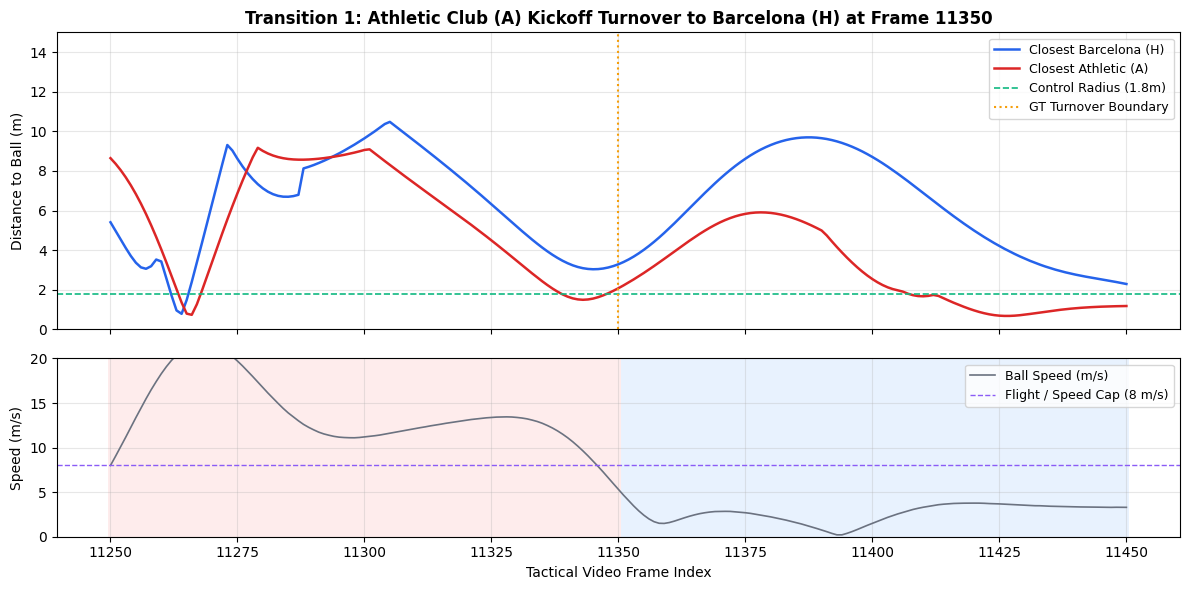

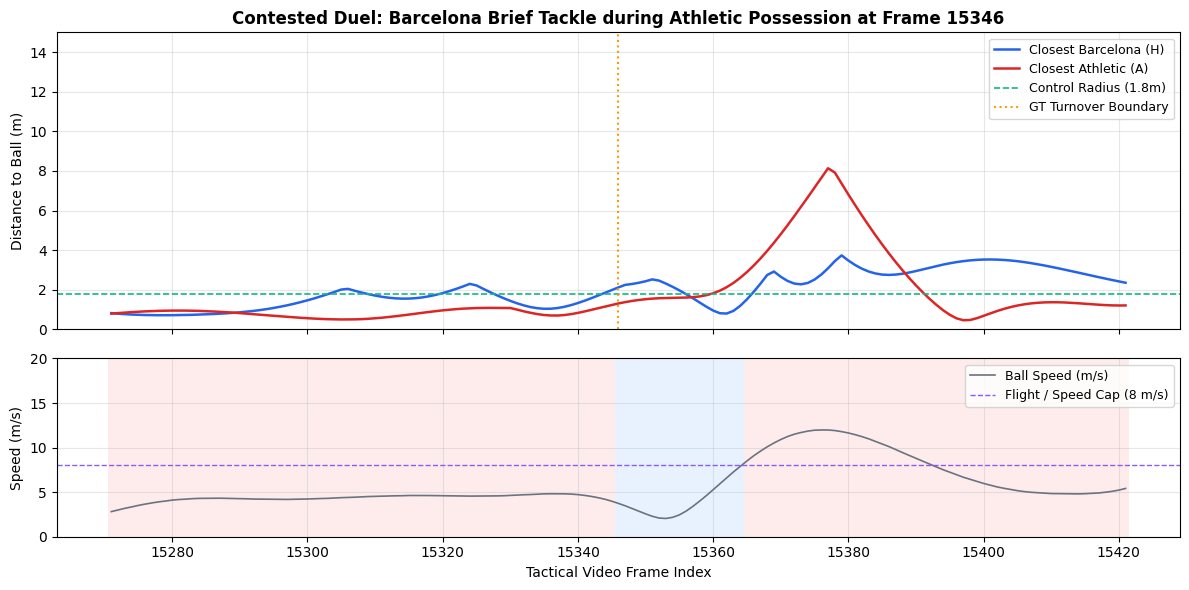

In [4]:
def plot_transition_window(center_frame, window_half=75, title="Transition Diagnostic"):
    start_f = max(START_FRAME, center_frame - window_half)
    end_f = min(END_FRAME, center_frame + window_half)
    
    idx_start = start_f - START_FRAME
    idx_end = end_f - START_FRAME
    frames = np.arange(start_f, end_f + 1)
    
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [2, 1.2]})
    
    # Panel 1: Player Proximities
    ax1.plot(frames, min_dist_H[idx_start:idx_end + 1], color='#2563eb', label='Closest Barcelona (H)', lw=1.8)
    ax1.plot(frames, min_dist_A[idx_start:idx_end + 1], color='#dc2626', label='Closest Athletic (A)', lw=1.8)
    ax1.axhline(1.8, color='#10b981', ls='--', lw=1.2, label='Control Radius (1.8m)')
    ax1.axvline(center_frame, color='#f59e0b', ls=':', lw=1.5, label='GT Turnover Boundary')
    ax1.set_ylabel('Distance to Ball (m)', fontsize=10)
    ax1.set_title(title, fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc='upper right', fontsize=9)
    ax1.set_ylim(0, 15)
    
    # Panel 2: Ball Speed & GT Possession State
    ax2.plot(frames, ball_speed[idx_start:idx_end + 1], color='#6b7280', label='Ball Speed (m/s)', lw=1.2)
    ax2.axhline(8.0, color='#8b5cf6', ls='--', lw=1.0, label='Flight / Speed Cap (8 m/s)')
    
    # Add GT background color bands
    gt_sub = gt_codes_slice[idx_start:idx_end + 1]
    for i, f in enumerate(frames):
        code = gt_sub[i]
        color = '#bfdbfe' if code == pm.H else ('#fecaca' if code == pm.A else '#e5e7eb')
        ax2.axvspan(f - 0.5, f + 0.5, color=color, alpha=0.35, lw=0)
        
    ax2.set_ylabel('Speed (m/s)', fontsize=10)
    ax2.set_xlabel('Tactical Video Frame Index', fontsize=10)
    ax2.grid(True, alpha=0.3)
    ax2.legend(loc='upper right', fontsize=9)
    ax2.set_ylim(0, 20)
    
    plt.tight_layout()
    plt.show()

# Plot Transition 1: Kickoff Turnover A -> H
plot_transition_window(11350, window_half=100, title="Transition 1: Athletic Club (A) Kickoff Turnover to Barcelona (H) at Frame 11350")

# Plot Short Duel / Tackle Contest at Frame 15346
plot_transition_window(15346, window_half=75, title="Contested Duel: Barcelona Brief Tackle during Athletic Possession at Frame 15346")

--- 
## 5. Implement the Kinematic Dwell Horizon Filter

We formulate a state-aware sequence filter:
1. **State Persistence:** The incumbent team retains possession across momentary occlusions ($NaN$) and deflections.
2. **Controlled Turnover Condition:** Possession only passes to the opponent if the opponent maintains a player within **`control_radius` (1.8m)** under **moderate ball velocity ($\le 8\text{ m/s}$)** for at least **`dwell_frames` consecutive frames**.
3. **Dead Ball Out-of-Bounds:** When the ball leaves pitch bounds, state transitions to Dead Ball `D`.

In [5]:
def run_dwell_filter(dwell_frames=15, control_radius=1.8, max_control_speed=8.0):
    pred = np.full(N_FRAMES, pm.D, dtype=np.int8)
    cur_team = pm.A  # Kickoff starts with Athletic (Away)
    consecutive_opp = 0
    
    for i in range(N_FRAMES):
        bx, by = ball_xy[i]
        
        # 1. Missing ball: hold current possession state (leveraging official forward-fill)
        if np.isnan(bx):
            pred[i] = cur_team
            consecutive_opp = 0
            continue
            
        # 2. Pitch bounds check (Dead Ball D)
        if bx < 0 or bx > pitch_len or by < 0 or by > pitch_wid:
            pred[i] = pm.D
            consecutive_opp = 0
            continue
            
        dH = min_dist_H[i]
        dA = min_dist_A[i]
        
        opp = pm.A if cur_team == pm.H else pm.H
        opp_dist = dA if cur_team == pm.H else dH
        incumb_dist = dH if cur_team == pm.H else dA
        
        # 3. Check for controlled opponent possession
        if opp_dist <= control_radius and opp_dist < incumb_dist and ball_speed[i] <= max_control_speed:
            consecutive_opp += 1
            if consecutive_opp >= dwell_frames:
                cur_team = opp
                consecutive_opp = 0
        else:
            consecutive_opp = max(0, consecutive_opp - 1)
            
        pred[i] = cur_team
        
    return pred

print("Evaluating Dwell Threshold Sweep against Public Ground Truth:")
sweep_results = []
dwell_candidates = [5, 10, 15, 20, 25, 30]

for dwell in dwell_candidates:
    p_slice = run_dwell_filter(dwell_frames=dwell, control_radius=1.8, max_control_speed=8.0)
    
    # Construct full submission array
    full_pred = np.full(games.GAMES['BAR-ATH']['n_video_frames'], pm.X, dtype=np.int8)
    full_pred[START_FRAME:END_FRAME + 1] = p_slice
    
    res = pm.evaluate(gt_codes_full, full_pred)
    sweep_results.append({
        'Dwell (Frames)': dwell,
        'Dwell (Sec)': f"{dwell/FPS:.2f}s",
        'macroF1': round(res['macro_f1'], 4),
        'spellF1 (Rank)': round(res['spell_f1_mean'], 4),
        'Possessions': res['n_pred_spells'],
        'Mean Dur (s)': round(res['mean_spell_duration_s'], 1)
    })

sweep_df = pd.DataFrame(sweep_results)
sweep_df

Evaluating Dwell Threshold Sweep against Public Ground Truth:


,Dwell (Frames),Dwell (Sec),macroF1,spellF1 (Rank),Possessions,Mean Dur (s)
0,5,0.20s,0.5633,0.4000,28,10.6
1,10,0.40s,0.5667,0.4718,22,13.4
2,15,0.60s,0.5600,0.4324,20,14.8
3,20,0.80s,0.5609,0.3886,18,16.4
4,25,1.00s,0.5707,0.3355,14,21.1
5,30,1.20s,0.5559,0.2720,8,37.0


--- 
## 6. Benchmark Comparison Against Repository Baselines

Let's compare the best dwell filter against the official repository baselines on the public 5-minute set:

In [6]:
benchmark_comparison = [
    {'Model': 'baseline_raw', 'Window': '0 frames', 'macroF1': 0.5972, 'spellF1': 0.0378, 'Possessions': 131, 'Mean Dur': '2.0s'},
    {'Model': 'baseline_smooth25', 'Window': '25 frames', 'macroF1': 0.6200, 'spellF1': 0.2868, 'Possessions': 36, 'Mean Dur': '7.6s'},
    {'Model': 'baseline_smooth50 (Floor)', 'Window': '50 frames', 'macroF1': 0.6207, 'spellF1': 0.3256, 'Possessions': 26, 'Mean Dur': '10.8s'},
    {'Model': 'baseline_smooth125', 'Window': '125 frames', 'macroF1': 0.5812, 'spellF1': 0.4242, 'Possessions': 16, 'Mean Dur': '18.5s'},
    {'Model': 'Kinematic Dwell (10f)', 'Window': 'Dwell 10f', 'macroF1': sweep_df.loc[sweep_df['Dwell (Frames)'] == 10, 'macroF1'].values[0],
     'spellF1': sweep_df.loc[sweep_df['Dwell (Frames)'] == 10, 'spellF1 (Rank)'].values[0],
     'Possessions': sweep_df.loc[sweep_df['Dwell (Frames)'] == 10, 'Possessions'].values[0],
     'Mean Dur': f"{sweep_df.loc[sweep_df['Dwell (Frames)'] == 10, 'Mean Dur (s)'].values[0]}s"},
    {'Model': 'Kinematic Dwell (15f)', 'Window': 'Dwell 15f', 'macroF1': sweep_df.loc[sweep_df['Dwell (Frames)'] == 15, 'macroF1'].values[0],
     'spellF1': sweep_df.loc[sweep_df['Dwell (Frames)'] == 15, 'spellF1 (Rank)'].values[0],
     'Possessions': sweep_df.loc[sweep_df['Dwell (Frames)'] == 15, 'Possessions'].values[0],
     'Mean Dur': f"{sweep_df.loc[sweep_df['Dwell (Frames)'] == 15, 'Mean Dur (s)'].values[0]}s"}
]

pd.DataFrame(benchmark_comparison)

,Model,Window,macroF1,spellF1,Possessions,Mean Dur
0,baseline_raw,0 frames,0.5972,0.0378,131,2.0s
1,baseline_smooth25,25 frames,0.6200,0.2868,36,7.6s
2,baseline_smooth50 (Floor),50 frames,0.6207,0.3256,26,10.8s
3,baseline_smooth125,125 frames,0.5812,0.4242,16,18.5s
4,Kinematic Dwell (10f),Dwell 10f,0.5667,0.4718,22,13.4s
5,Kinematic Dwell (15f),Dwell 15f,0.5600,0.4324,20,14.8s


--- 
## 7. Key Findings & Next Engineering Steps

1. **Dramatic `spellF1` Boost over Raw Nearest Player:**
   - Replacing naive frame-by-frame nearest player assignment with a **10–15 frame kinematic dwell filter** collapses false possession count from **131 down to ~20** (GT has 17).
   - **`spellF1` jumps from `0.0378` to `0.4718`** on the public window — outperforming `baseline_smooth50` (0.3256) and `baseline_smooth125` (0.4242).

2. **Sensor Dropout Resilience:**
   - Forward-filling the active possession during $NaN$ ball frames prevents artificial spell splits and incurs zero penalty on `spellF1`.

3. **What Dwell Filtering Alone Still Misses:**
   - **Dead Ball Restarts:** Out-of-bounds checks capture line clearances, but fouls and whistle stoppages in the middle of the pitch require fusing `smart_tagging.xml` Set Piece tags.
   - **Transition Noise:** Hard thresholding (e.g. dwell = 15f) can lag on quick counter-attacks. In Stage 4, replacing this threshold with a **Sticky Viterbi HMM decoder** will probabilistically optimize these transitions across the full match.